In [35]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [36]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/../utils/train_utils.py'>

In [37]:
read_ids = list(range(0, 12+1))
read_ids = [0, 2, 3, 6, 8, 9]
plot_id = 0

In [38]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# raw

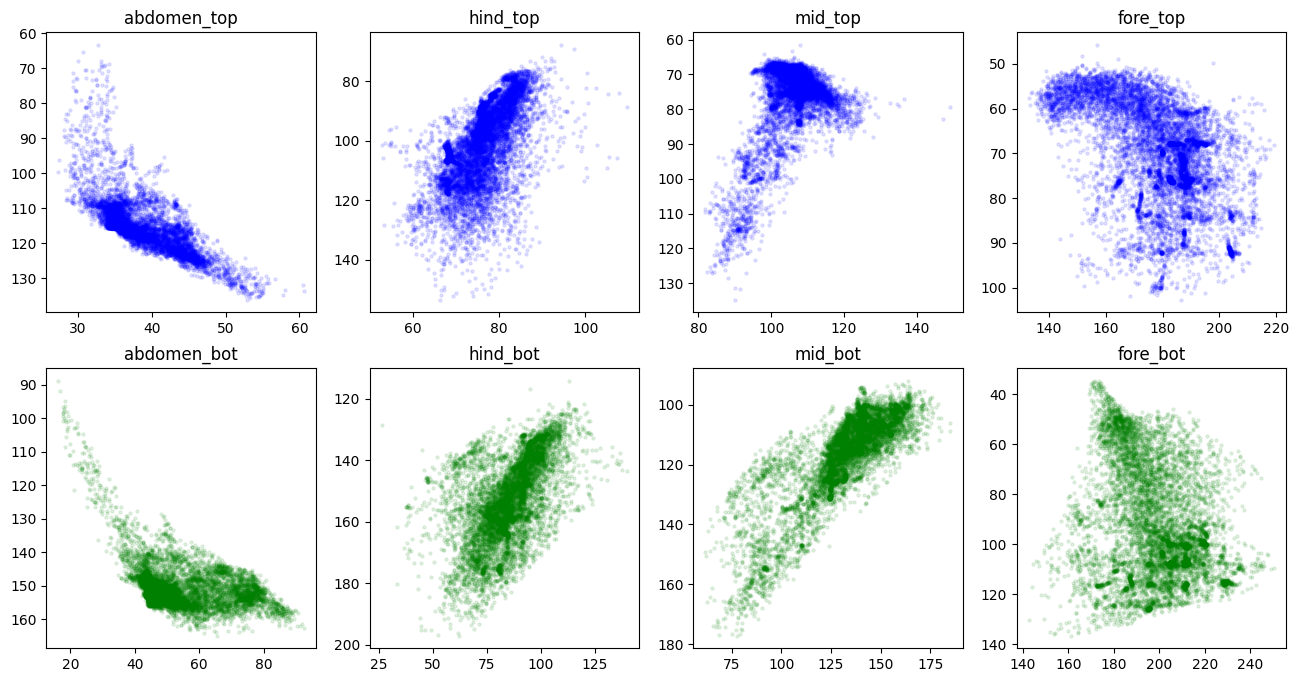

In [39]:
plot_utils.plot_markers(markers[file_ids.index(plot_id)], join_topbot=False)

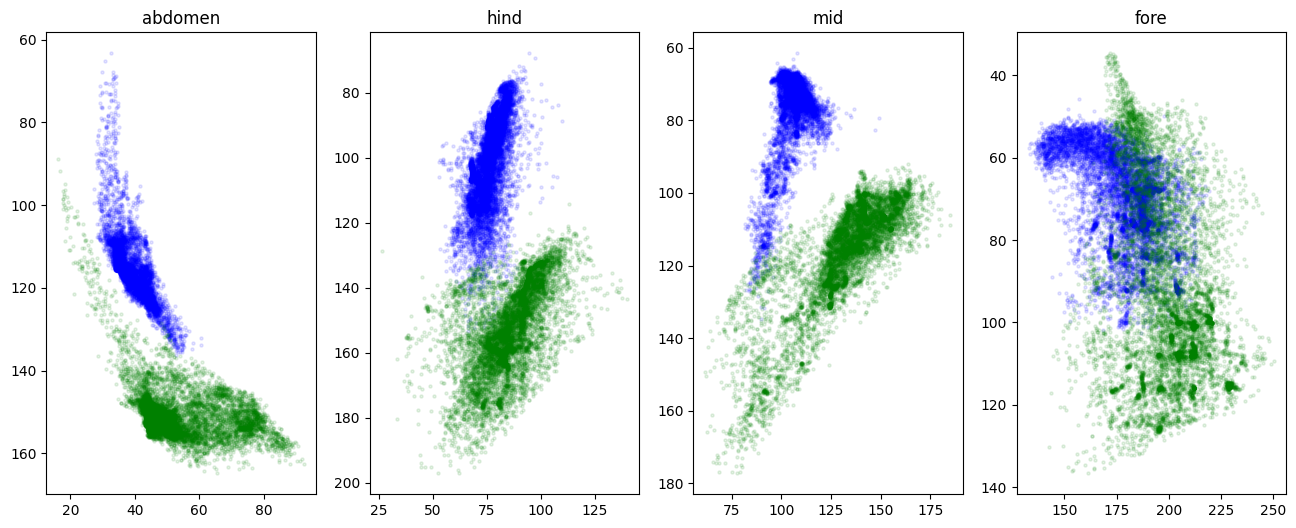

In [40]:
plot_utils.plot_markers(markers[file_ids.index(plot_id)], join_topbot=True)

In [41]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]

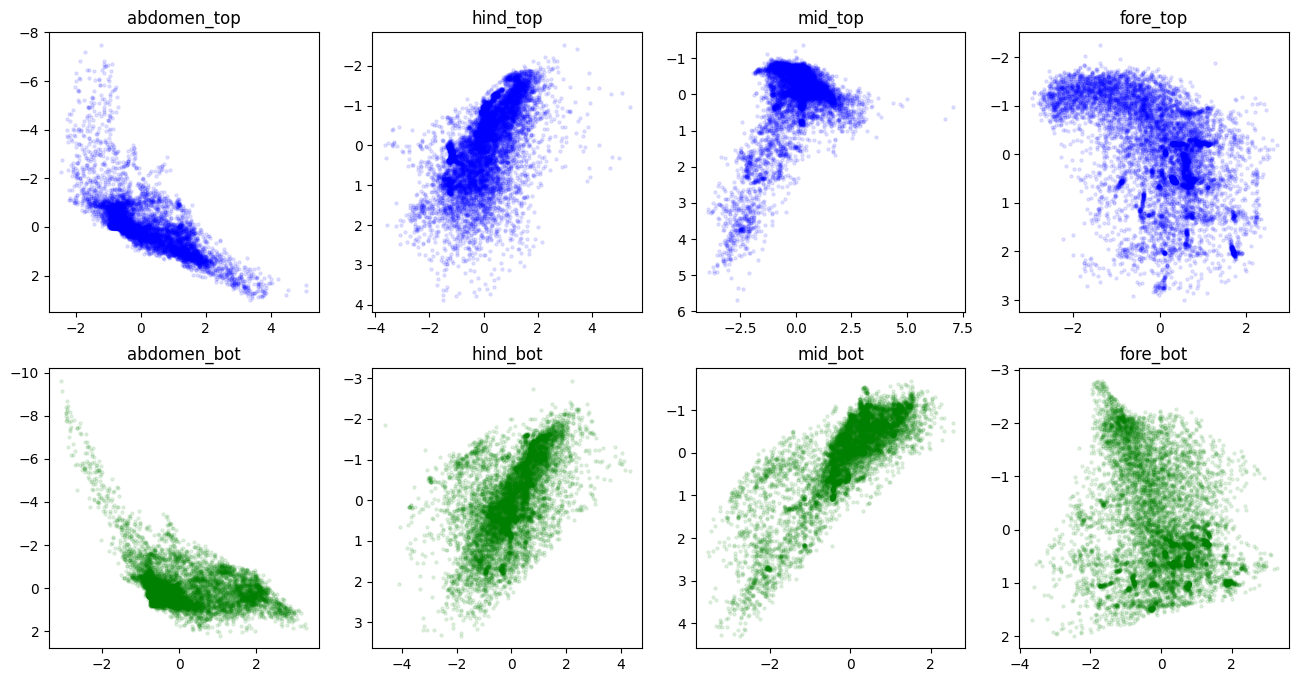

In [42]:
plot_utils.plot_markers(markers_zs[file_ids.index(plot_id)], join_topbot=False)

# relative

In [43]:
markers_rel = markers.copy()

for file_id in file_ids:
	marker = markers_rel[file_ids.index(file_id)]
	for label in marker.columns[::4]:
		label = label.split('-')[0]
		marker[f'{label}-bot_x'] -= marker[f'{label}-top_x']
		marker[f'{label}-bot_y'] -= marker[f'{label}-top_y']

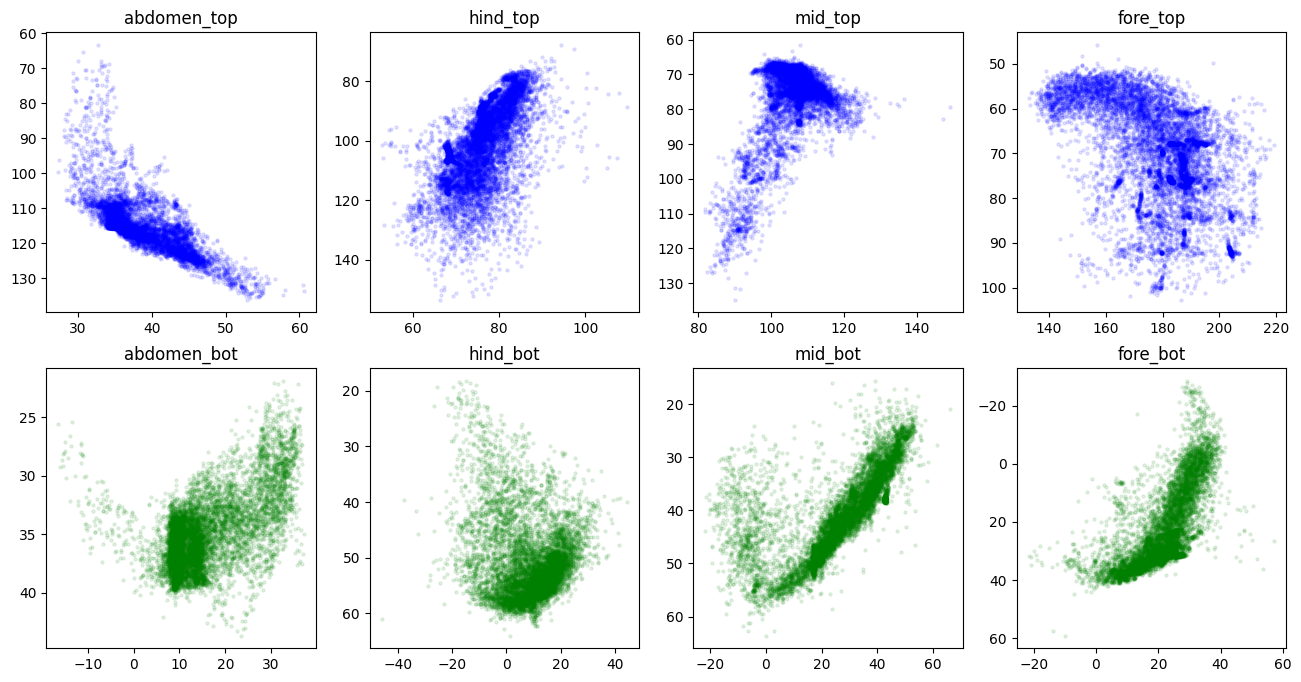

In [44]:
plot_utils.plot_markers(markers_rel[file_ids.index(plot_id)], join_topbot=False)

In [45]:
markers_rel_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers_rel
]

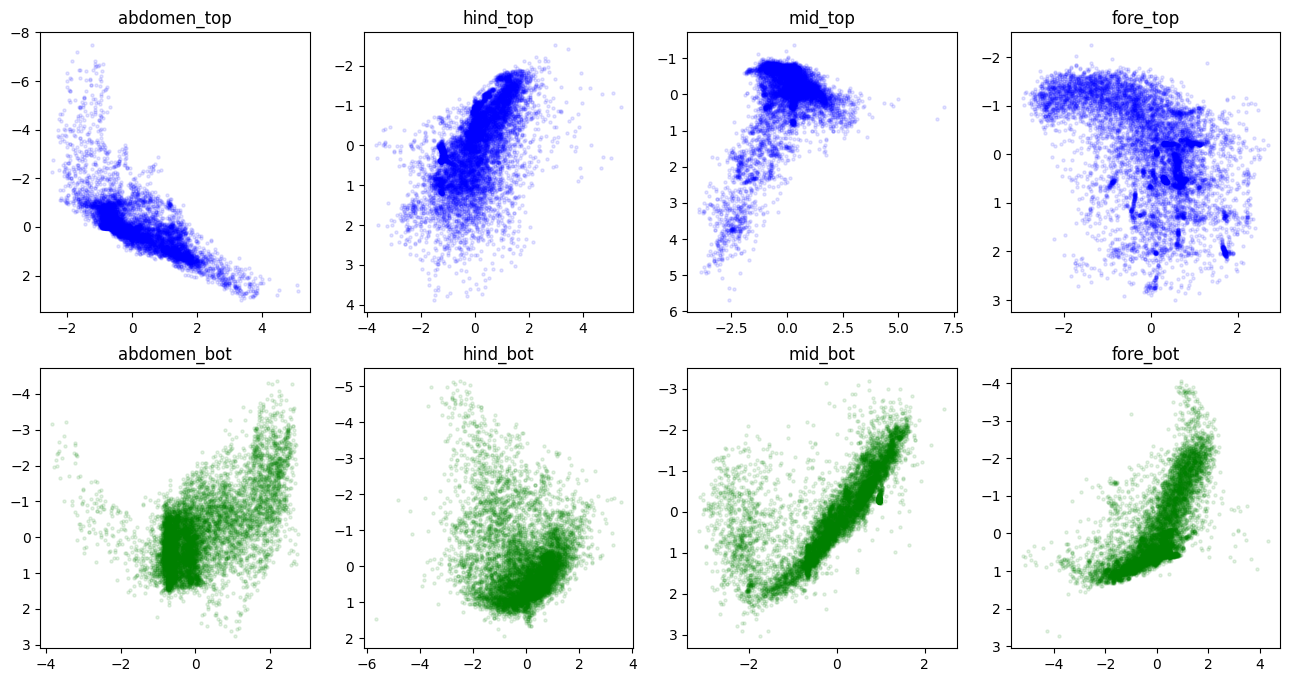

In [46]:
plot_utils.plot_markers(markers_rel_zs[file_ids.index(plot_id)], join_topbot=False)

# PCA raw

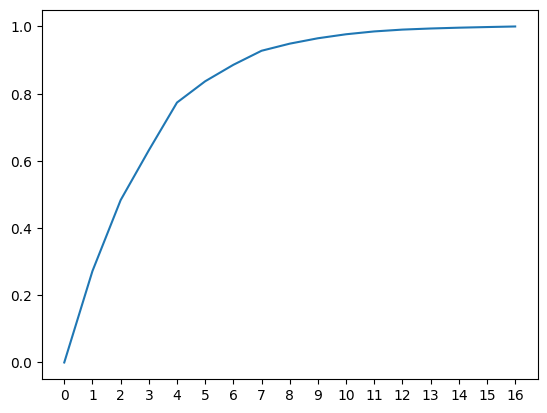

In [47]:
n_pc = 16
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[file_ids.index(plot_id)].values)
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
plt.xticks(range(16+1))
pass

In [48]:
n_pc = 8
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[file_ids.index(plot_id)])
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

# plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
# plt.xticks(range(n_pc+1))
print(np.sum(vars_expl[:vars_expl.shape[0]]))

0.9488697248342737


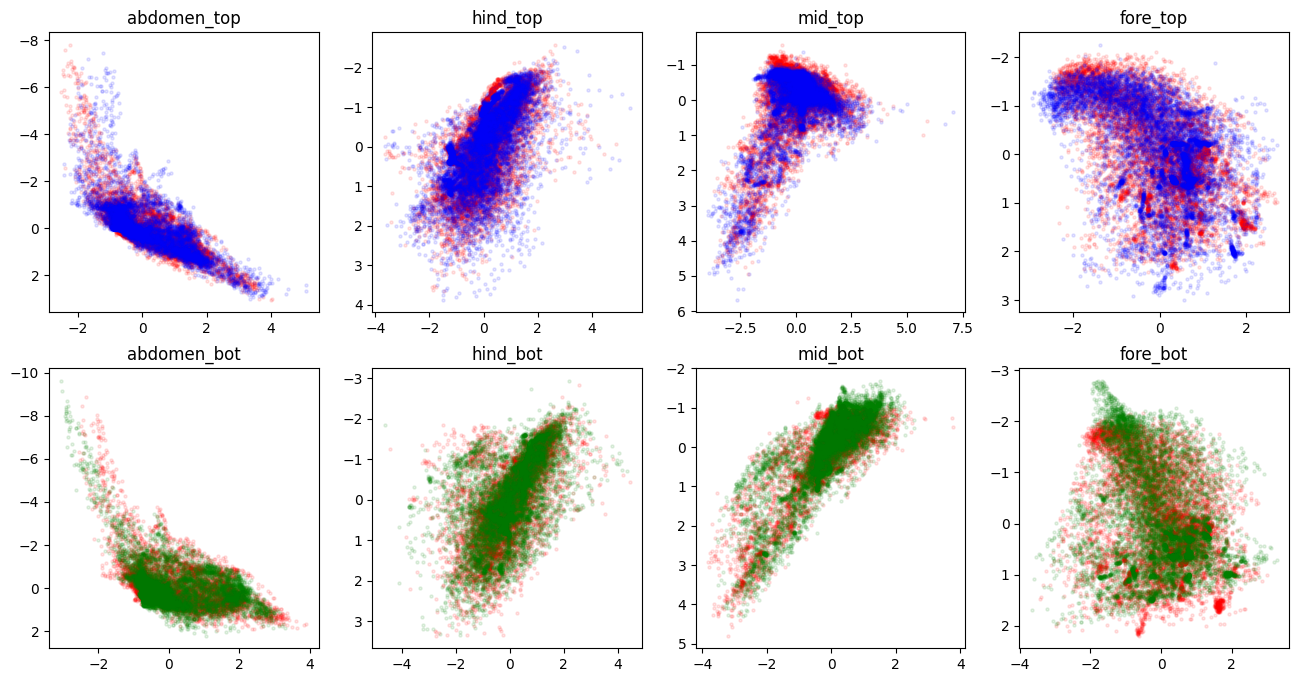

In [49]:
plot_utils.plot_markers(markers_zs[file_ids.index(plot_id)], recon, join_topbot=False)

# PCA rel

In [50]:
n_pc = 8
pca = PCA(n_components=n_pc)
markers_rel_zs_reduced = pca.fit_transform(markers_rel_zs[file_ids.index(plot_id)])
markers_rel_zs_reconstructed = pca.inverse_transform(markers_rel_zs_reduced)
modes = pd.DataFrame(data=markers_rel_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_rel_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

# plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
# plt.xticks(range(n_pc+1))
print(np.sum(vars_expl[:vars_expl.shape[0]]))

0.8737854949046491


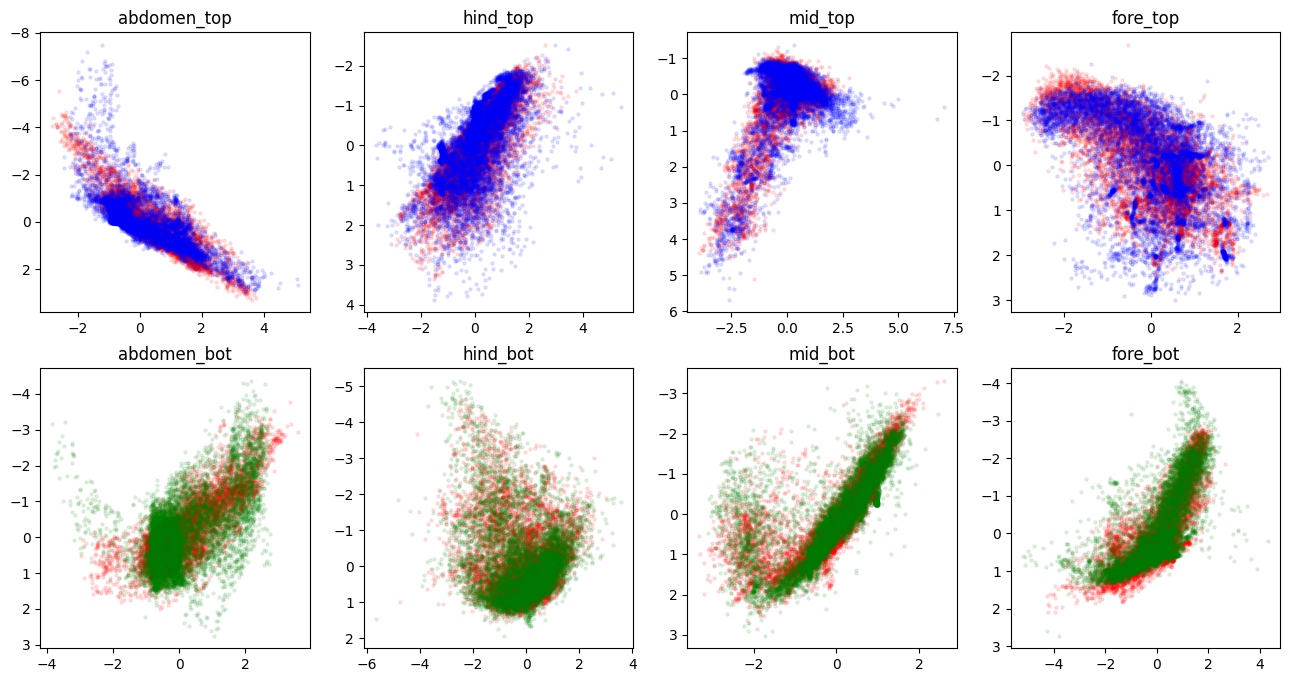

In [51]:
plot_utils.plot_markers(markers_rel_zs[file_ids.index(plot_id)], recon, join_topbot=False)

# diff

In [52]:
markers_diff = [pd.DataFrame(data=marker.values[1:, :] - marker.values[:-1, :], columns=marker.columns) for marker in markers]
markers_diff_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers_diff
]

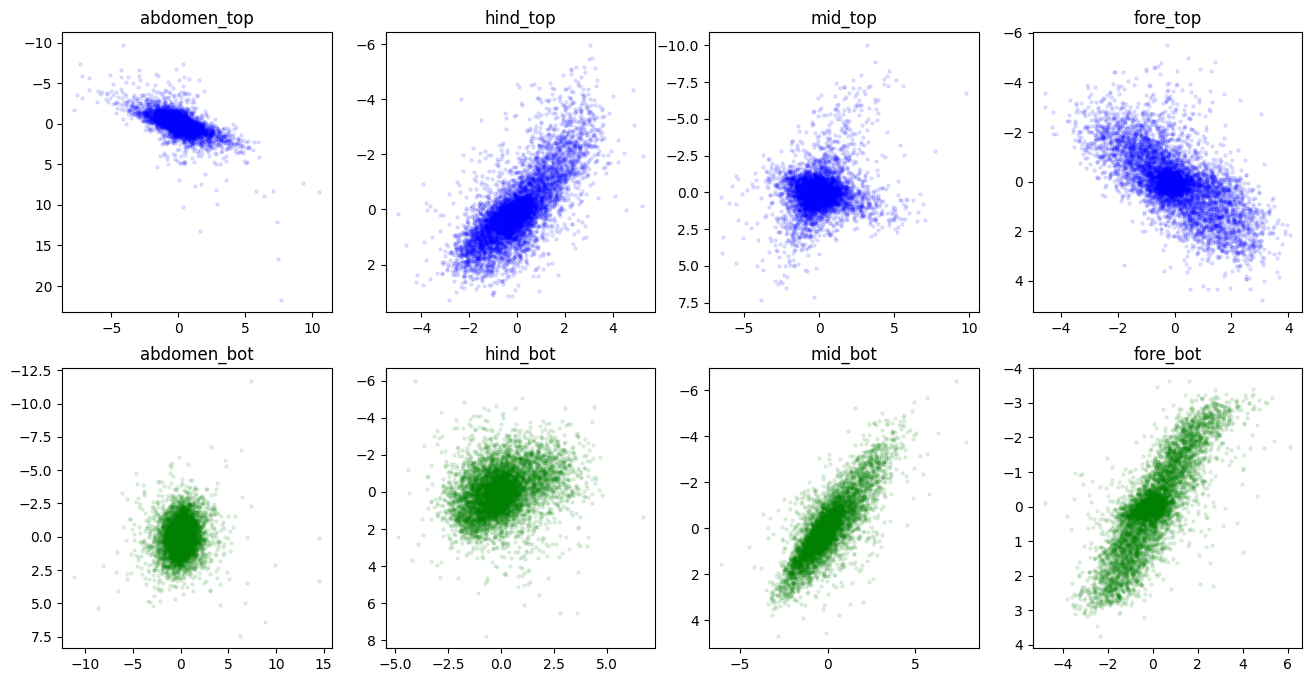

In [53]:
plot_utils.plot_markers(markers_diff_zs[file_ids.index(plot_id)], join_topbot=False)

# rel diff

In [54]:
markers_rel_diff = [pd.DataFrame(data=marker.values[1:, :] - marker.values[:-1, :], columns=marker.columns) for marker in markers_rel]
markers_rel_diff_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers_rel_diff
]

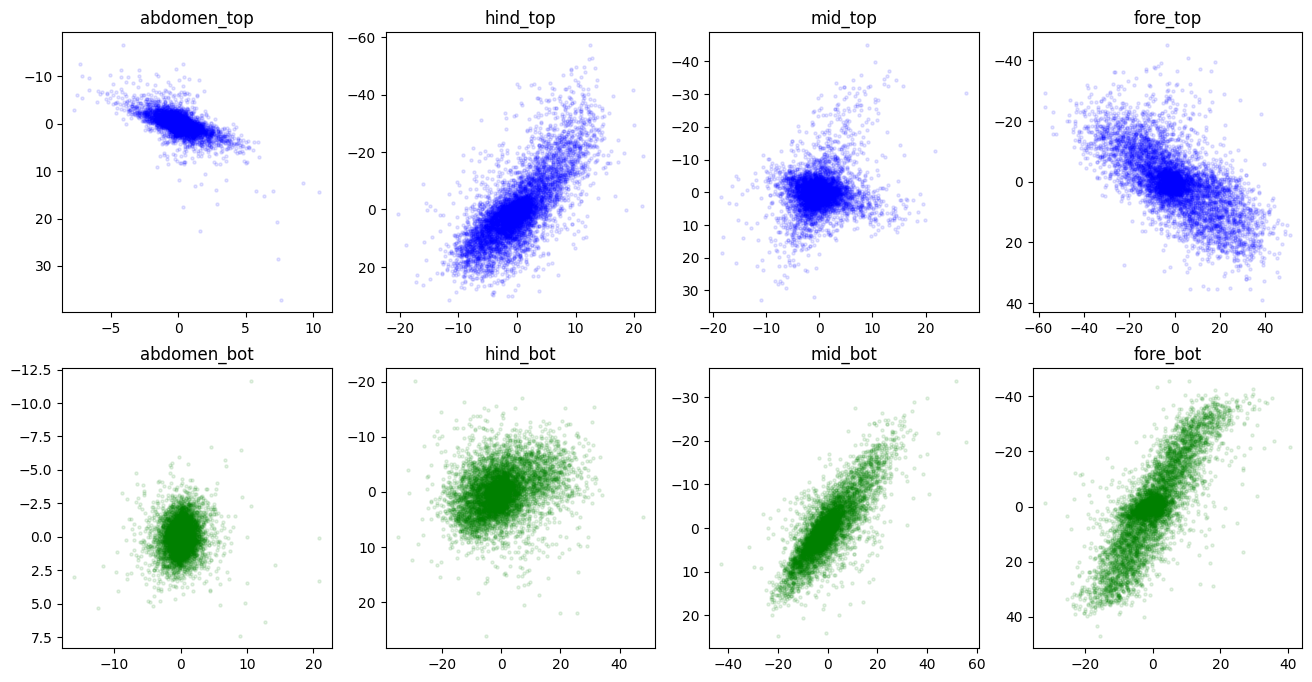

In [55]:
plot_utils.plot_markers(markers_rel_diff[file_ids.index(plot_id)], join_topbot=False)